# Data Exploration and Visualization – Complete 5-Unit Assignment
**Dataset:** Plotly Express `tips` dataset

This notebook covers all five units: EDA, Matplotlib/Seaborn/Plotly/Bokeh, univariate analysis, bivariate analysis, multivariate analysis, PCA/t-SNE and a basic scikit-learn model.

In [5]:
pip install plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
   ---------------------------------------- 0.0/474.0 kB ? eta -:--:--
    --------------------------------------- 10.2/474.0 kB ? eta -:--:--
    --------------------------------------- 10.2/474.0 kB ? eta -:--:--
   --- ----------------------------------- 41.0/474.0 kB 326.8 kB/s eta 0:00:02
   ------- ------------------------------- 92.2/474.0 kB 581.0 kB/s eta 0:00:01
   --------------- ---------------------- 194.6/474.0 kB 980.4 kB/s eta 0:00:01
   ------------------------- -------------- 307.2/474.0 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 474.0/474.0 kB 1.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, plotly.express as px
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
sns.set_theme(style="whitegrid")
df=pd.read_csv("data/tips.csv")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## UNIT 1 – Exploratory Data Analysis

In [7]:
print("Shape:",df.shape)
print("\nData types:"); print(df.dtypes)
print("\nMissing values:"); display(df.isna().sum().to_frame("missing_count"))
print("\nDuplicate rows:",df.duplicated().sum())
display(df.describe(include="all"))

Shape: (244, 7)

Data types:
total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object

Missing values:


,missing_count
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0



Duplicate rows: 1


,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


In [8]:
df=df.drop_duplicates().copy()
encoded=pd.get_dummies(df[["sex","smoker","day","time"]],drop_first=True,dtype=int)
df["log_total_bill"]=np.log1p(df["total_bill"])
df["tip_percentage"]=df["tip"]/df["total_bill"]*100
display(encoded.head())
display(df.groupby("day",observed=True)["total_bill"].agg(["count","mean","median","sum"]).round(3))

,sex_Male,smoker_Yes,day_Sat,day_Sun,day_Thur,time_Lunch
0,0,0,0,1,0,0
1,1,0,0,1,0,0
2,1,0,0,1,0,0
3,1,0,0,1,0,0
4,0,0,0,1,0,0


,count,mean,median,sum
day,,,,
Fri,19,17.152,15.38,325.88
Sat,87,20.441,18.24,1778.40
Sun,76,21.410,19.63,1627.16
Thur,61,17.760,16.40,1083.33


## UNIT 2 – Visualizing Using Matplotlib

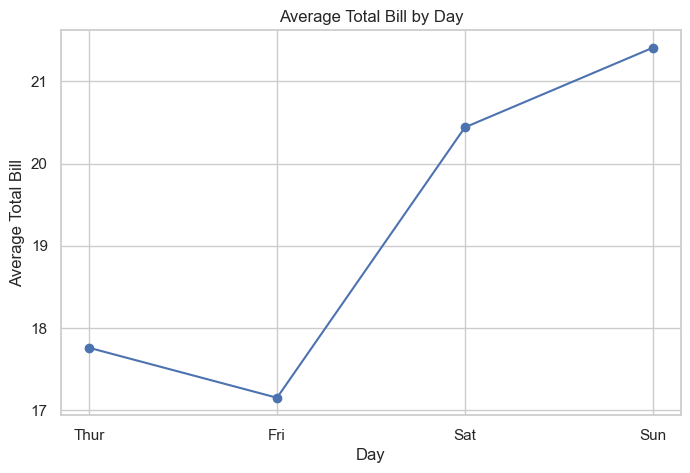

In [9]:
daily=df.groupby("day",observed=True)["total_bill"].mean().reindex(["Thur","Fri","Sat","Sun"])
plt.figure(figsize=(8,5)); plt.plot(daily.index,daily.values,marker="o")
plt.title("Average Total Bill by Day"); plt.xlabel("Day"); plt.ylabel("Average Total Bill"); plt.show()

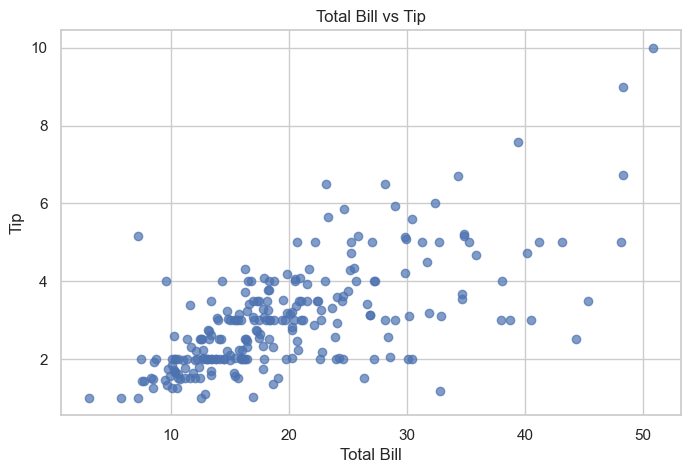

In [10]:
plt.figure(figsize=(8,5)); plt.scatter(df["total_bill"],df["tip"],alpha=.7)
plt.title("Total Bill vs Tip"); plt.xlabel("Total Bill"); plt.ylabel("Tip"); plt.show()

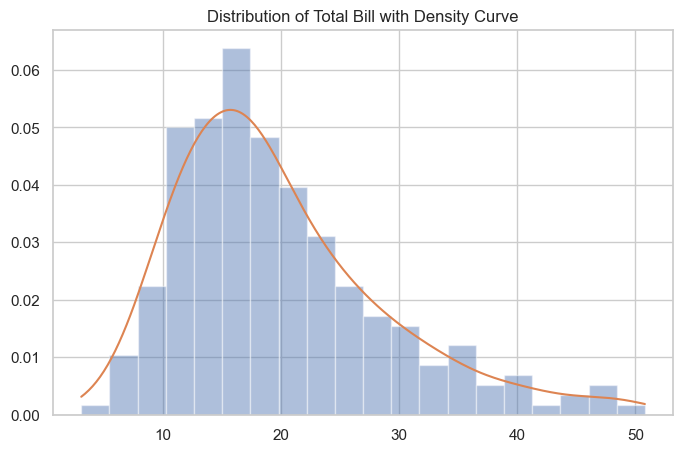

In [11]:
x=df["total_bill"].to_numpy(); grid=np.linspace(x.min(),x.max(),300)
plt.figure(figsize=(8,5)); plt.hist(x,bins=20,density=True,alpha=.45); plt.plot(grid,gaussian_kde(x)(grid))
plt.title("Distribution of Total Bill with Density Curve"); plt.show()

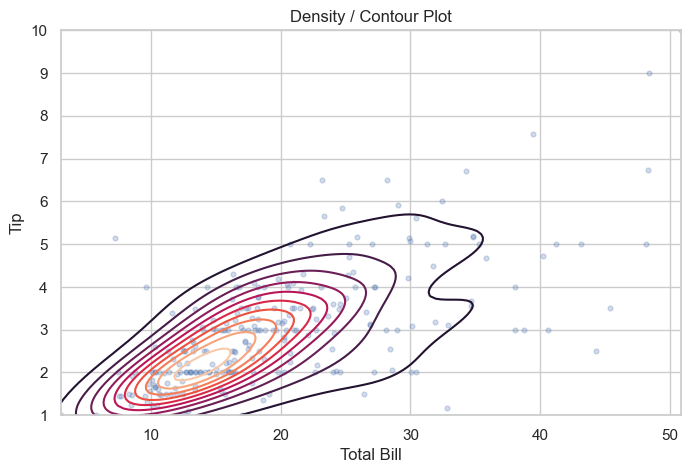

In [12]:
x=df["total_bill"].to_numpy(); y=df["tip"].to_numpy()
kde=gaussian_kde(np.vstack([x,y])); gx=np.linspace(x.min(),x.max(),120); gy=np.linspace(y.min(),y.max(),120)
GX,GY=np.meshgrid(gx,gy); Z=kde(np.vstack([GX.ravel(),GY.ravel()])).reshape(GX.shape)
plt.figure(figsize=(8,5)); plt.contour(GX,GY,Z,levels=10); plt.scatter(x,y,s=12,alpha=.25)
plt.title("Density / Contour Plot"); plt.xlabel("Total Bill"); plt.ylabel("Tip"); plt.show()

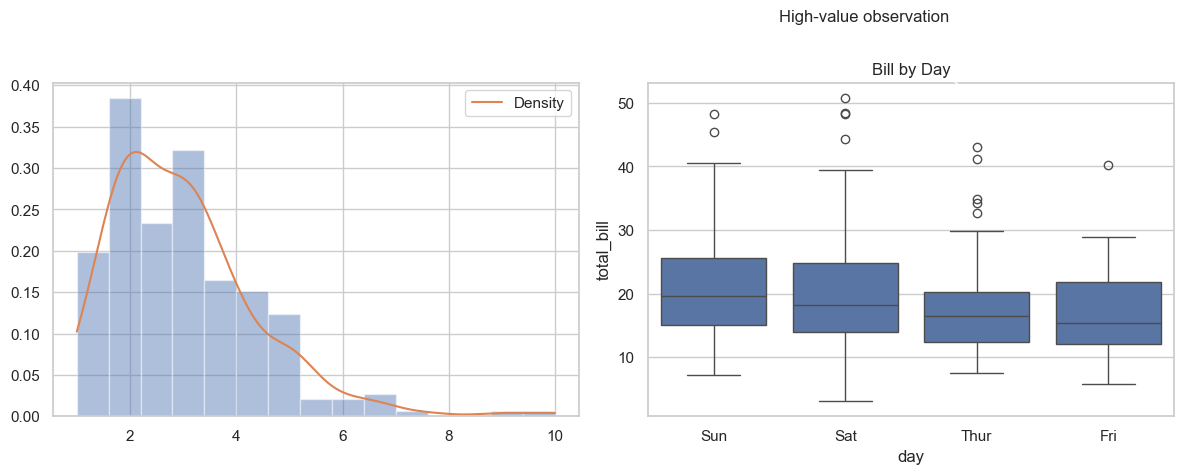

In [13]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
tx=np.linspace(df["tip"].min(),df["tip"].max(),200)
ax[0].hist(df["tip"],bins=15,density=True,alpha=.45); ax[0].plot(tx,gaussian_kde(df["tip"])(tx),label="Density"); ax[0].legend()
sns.boxplot(data=df,x="day",y="total_bill",ax=ax[1]); ax[1].set_title("Bill by Day")
ax[1].annotate("High-value observation",xy=(2,df["total_bill"].max()),xytext=(.5,df["total_bill"].max()+12),arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()

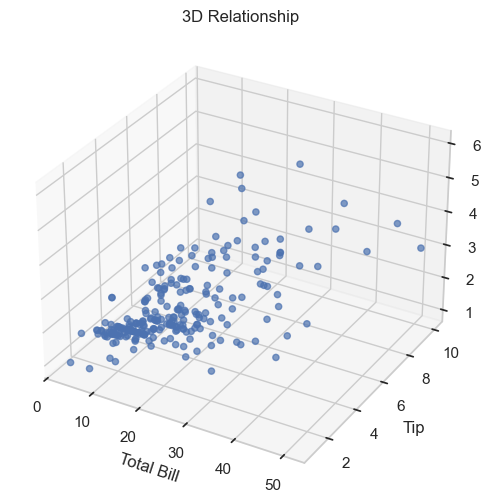

In [14]:
fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(111,projection="3d")
ax.scatter(df["total_bill"],df["tip"],df["size"],alpha=.7)
ax.set_xlabel("Total Bill"); ax.set_ylabel("Tip"); ax.set_zlabel("Party Size"); ax.set_title("3D Relationship"); plt.show()

In [ ]:
fig=px.scatter(df,x="total_bill",y="tip",color="sex",symbol="smoker",hover_data=["day","time","size"],title="Interactive Total Bill vs Tip"); fig.show()

In [17]:
pip install bokeh

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached pyyaml-6.0.3-cp311-cp311-win_amd64.whl.metadata (2.4 kB)
  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB 435.7 kB/s eta 0:00:15
   ---------------------------------------- 0.1/6.4 MB 563.7 kB/s eta 0:00:12
    --------------------------------------- 0.2/6.4 MB 919.0 kB/s eta 0:00:07
   - -------------------------------------- 0.3/6.4 MB 1.4 MB/s eta 0:00:05
   --- ------------------------------------ 0.5/6.4 MB 2.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.1/6.4 MB 3.6 MB/s eta 0:00:02
   ------------- -------------------------- 2.1/6.4 MB 6.0 MB/s eta 0:00:01
   --------------- ------------------------ 2.5/6.4 MB 6.3 MB/s eta 0:00:01
   ----------------------- ---------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from bokeh.plotting import figure,show
from bokeh.models import ColumnDataSource,HoverTool
source=ColumnDataSource(df)
p=figure(title="Bokeh: Total Bill vs Tip",x_axis_label="Total Bill",y_axis_label="Tip",width=800,height=450)
p.circle("total_bill","tip",source=source,size=7,alpha=.65)
p.add_tools(HoverTool(tooltips=[("Total Bill","@total_bill{0.00}"),("Tip","@tip{0.00}"),("Day","@day"),("Sex","@sex")]))
show(p)

## UNIT 3 – Univariate Analysis

In [20]:
display(df[["total_bill","tip","size"]].describe().round(3))
print("Skewness:"); display(df[["total_bill","tip","size"]].skew().round(3))
print("Quartiles:"); display(df[["total_bill","tip","size"]].quantile([.25,.5,.75]).round(3))

,total_bill,tip,size
count,243.000,243.000,243.000
mean,19.814,3.002,2.572
std,8.910,1.385,0.952
min,3.070,1.000,1.000
25%,13.380,2.000,2.000
50%,17.810,2.920,2.000
75%,24.175,3.575,3.000
max,50.810,10.000,6.000


Skewness:


total_bill    1.127
tip           1.460
size          1.442
dtype: float64

Quartiles:


,total_bill,tip,size
0.25,13.380,2.000,2.0
0.50,17.810,2.920,2.0
0.75,24.175,3.575,3.0


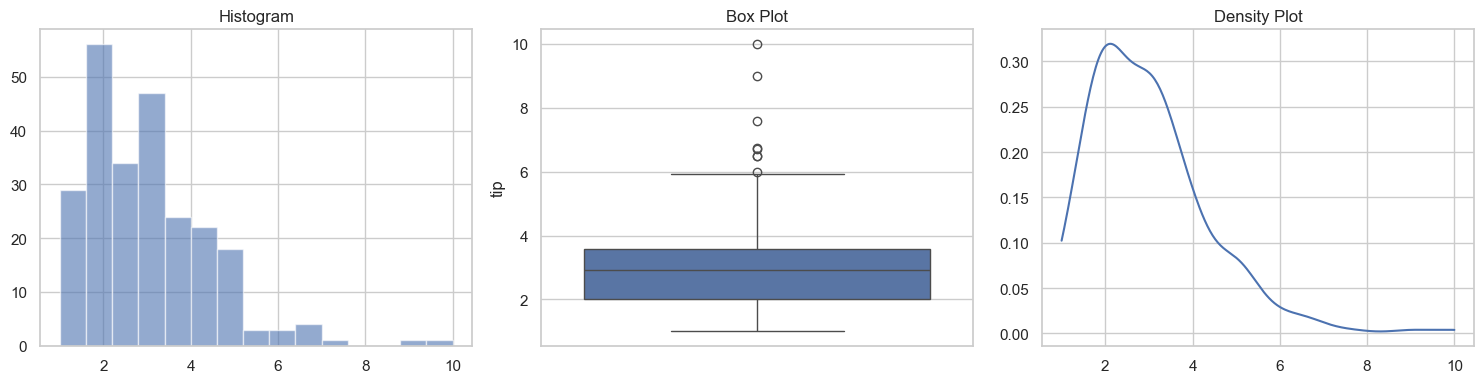

In [21]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].hist(df["tip"],bins=15,alpha=.6); ax[0].set_title("Histogram")
sns.boxplot(y=df["tip"],ax=ax[1]); ax[1].set_title("Box Plot")
tx=np.linspace(df["tip"].min(),df["tip"].max(),300); ax[2].plot(tx,gaussian_kde(df["tip"])(tx)); ax[2].set_title("Density Plot")
plt.tight_layout(); plt.show()

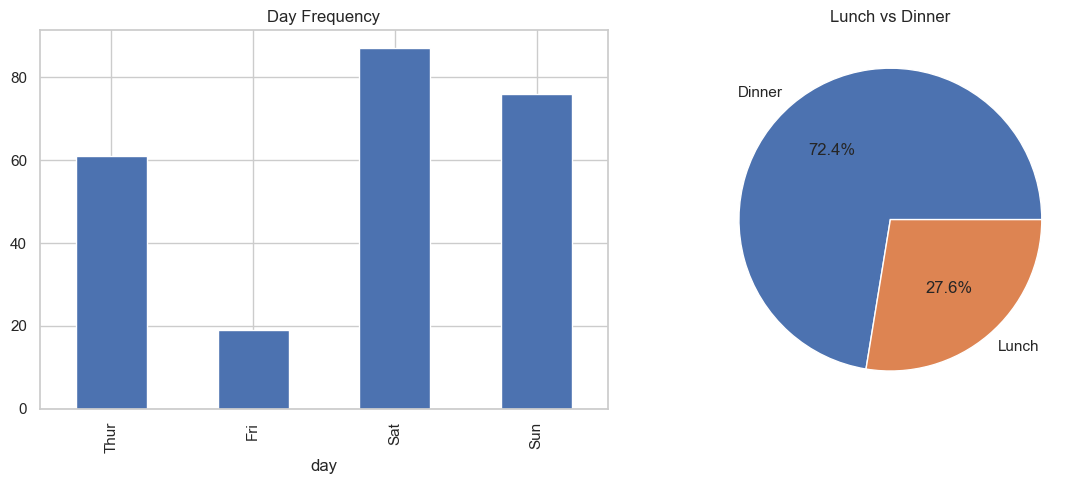

time,Dinner,Lunch
day,,
Fri,12,7
Sat,87,0
Sun,76,0
Thur,1,60


In [22]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
df["day"].value_counts().reindex(["Thur","Fri","Sat","Sun"]).plot(kind="bar",ax=ax[0],title="Day Frequency")
tc=df["time"].value_counts(); ax[1].pie(tc.values,labels=tc.index,autopct="%1.1f%%"); ax[1].set_title("Lunch vs Dinner")
plt.tight_layout(); plt.show()
display(pd.crosstab(df["day"],df["time"]))

## UNIT 4 – Bivariate Analysis

Pearson: 0.675
Spearman: 0.677


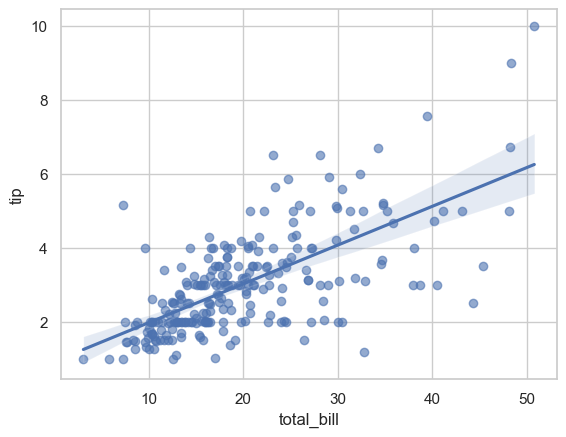

In [23]:
print("Pearson:",round(df["total_bill"].corr(df["tip"],method="pearson"),3))
print("Spearman:",round(df["total_bill"].corr(df["tip"],method="spearman"),3))
sns.regplot(data=df,x="total_bill",y="tip",scatter_kws={"alpha":.6}); plt.show()

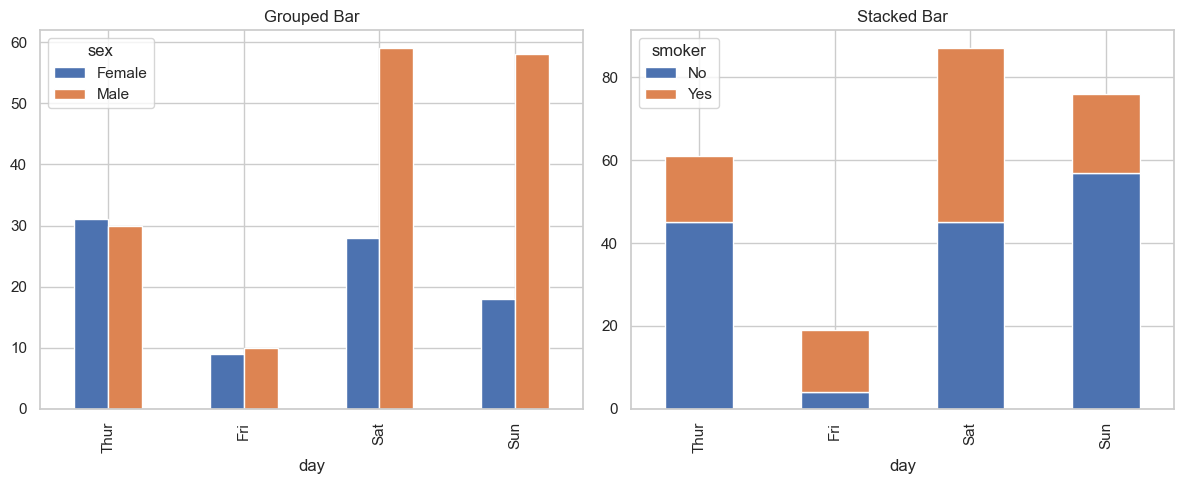

In [24]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
pd.crosstab(df["day"],df["sex"]).reindex(["Thur","Fri","Sat","Sun"]).plot(kind="bar",ax=ax[0],title="Grouped Bar")
pd.crosstab(df["day"],df["smoker"]).reindex(["Thur","Fri","Sat","Sun"]).plot(kind="bar",stacked=True,ax=ax[1],title="Stacked Bar")
plt.tight_layout(); plt.show()

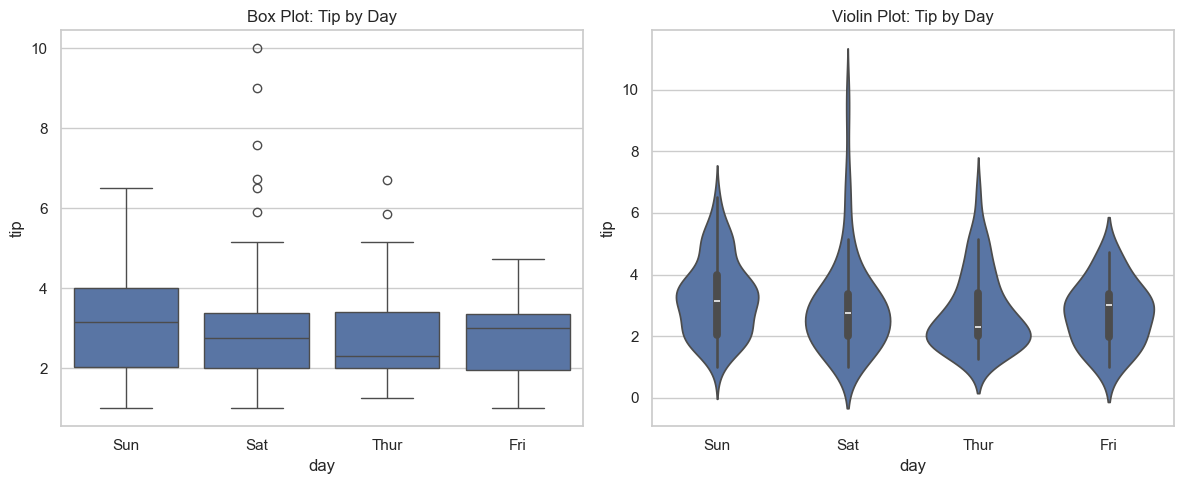

In [25]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
sns.boxplot(data=df,x="day",y="tip",ax=ax[0]); ax[0].set_title("Box Plot: Tip by Day")
sns.violinplot(data=df,x="day",y="tip",inner="box",ax=ax[1]); ax[1].set_title("Violin Plot: Tip by Day")
plt.tight_layout(); plt.show()

## UNIT 5 – Multivariate Analysis

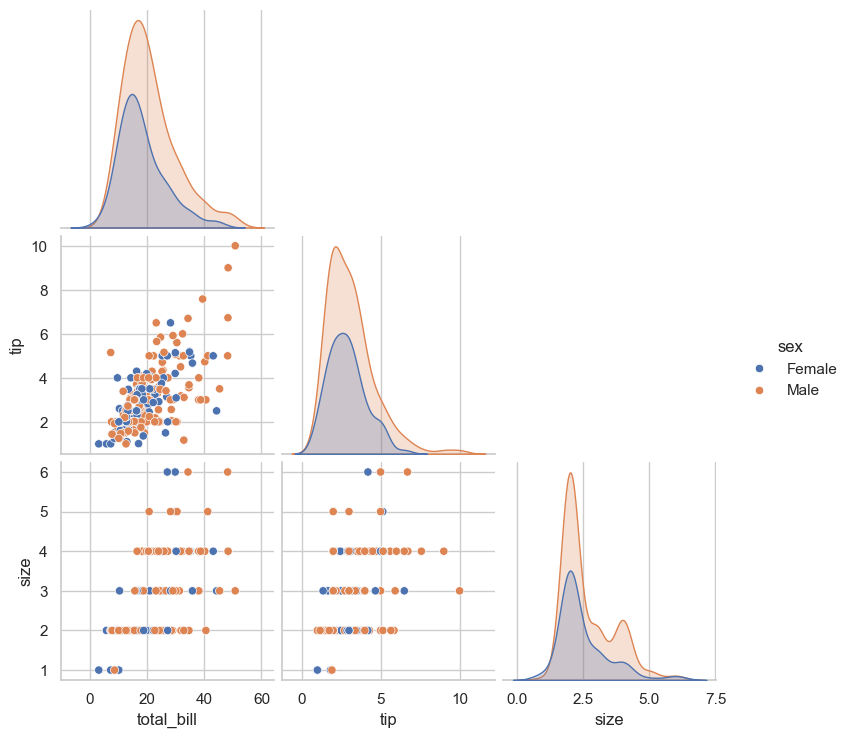

In [26]:
sns.pairplot(df[["total_bill","tip","size","sex"]],hue="sex",corner=True); plt.show()

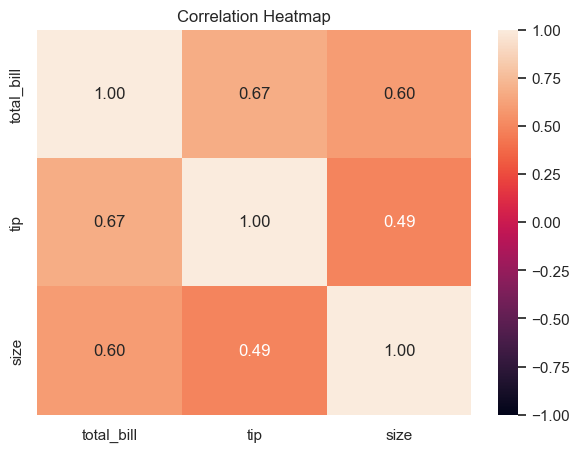

In [27]:
corr=df[["total_bill","tip","size"]].corr()
plt.figure(figsize=(7,5)); sns.heatmap(corr,annot=True,fmt=".2f",vmin=-1,vmax=1); plt.title("Correlation Heatmap"); plt.show()

Explained variance: [0.61083184 0.26071432]


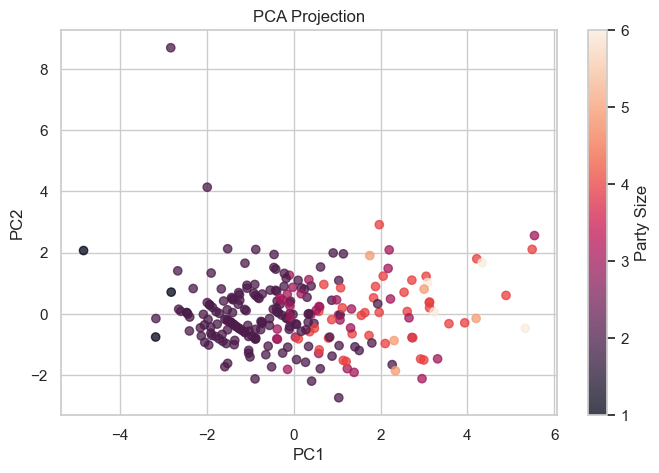

In [28]:
features=["total_bill","tip","size","tip_percentage","log_total_bill"]
X_scaled=StandardScaler().fit_transform(df[features]); pca=PCA(n_components=2); X_pca=pca.fit_transform(X_scaled)
print("Explained variance:",pca.explained_variance_ratio_)
plt.figure(figsize=(8,5)); plt.scatter(X_pca[:,0],X_pca[:,1],c=df["size"],alpha=.75); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA Projection"); plt.colorbar(label="Party Size"); plt.show()

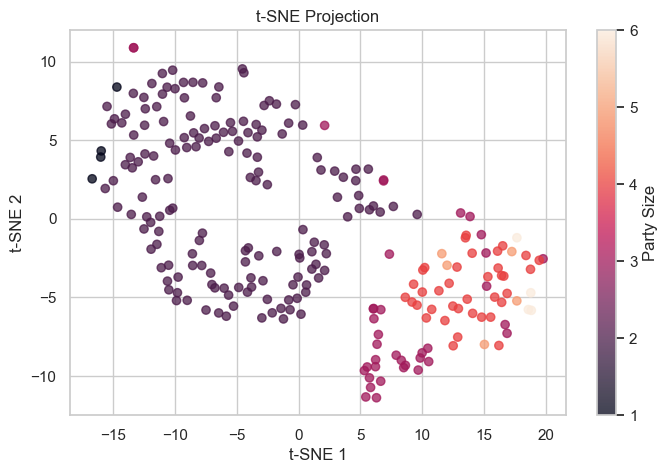

In [29]:
tsne=TSNE(n_components=2,random_state=42,perplexity=30,init="pca",learning_rate="auto")
X_tsne=tsne.fit_transform(X_scaled)
plt.figure(figsize=(8,5)); plt.scatter(X_tsne[:,0],X_tsne[:,1],c=df["size"],alpha=.75)
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.title("t-SNE Projection"); plt.colorbar(label="Party Size"); plt.show()

### Basic scikit-learn Model

In [30]:
features=["total_bill","size","sex","smoker","day","time"]; X=df[features]; y=df["tip"]
prep=ColumnTransformer([("num",StandardScaler(),["total_bill","size"]),("cat",OneHotEncoder(handle_unknown="ignore"),["sex","smoker","day","time"])])
model=Pipeline([("preprocessor",prep),("regressor",LinearRegression())])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42); model.fit(X_train,y_train); pred=model.predict(X_test)
print("MAE:",round(mean_absolute_error(y_test,pred),3)); print("RMSE:",round(mean_squared_error(y_test,pred)**.5,3)); print("R2:",round(r2_score(y_test,pred),3))

MAE: 0.767
RMSE: 1.083
R2: 0.519


## Final Observations
1. The dataset contains numerical and categorical variables.
2. No missing values were found; duplicate checking is performed and the duplicate is removed.
3. Total bill and tip show a positive relationship.
4. Histograms, density plots and box plots describe distributions and high-value observations.
5. Bar, pie, grouped and stacked charts summarize categorical patterns.
6. Pair plots and heatmaps reveal multivariate relationships.
7. PCA and t-SNE reduce the feature space for visualization.
8. Linear Regression demonstrates a basic scikit-learn workflow.